In [4]:
# Cell 1: Import dependencies
import pandas as pd
import matplotlib.pyplot as plt
import random
import math
from datetime import datetime

print("Smart-Grow :: Week 1 Validation Notebook")
print("Running on Google Colab infrastructure.")

Smart-Grow :: Week 1 Validation Notebook
Running on Google Colab infrastructure.


In [5]:
# Cell 2: Simulate 20 readings (representing 100 seconds of field data)
def simulate_field_reading(minute_of_day):
    temp_base  = 22.0 + 5.0 * math.sin((minute_of_day / 1440.0) * 2 * math.pi - math.pi / 2)
    temperature = round(temp_base + random.uniform(-0.4, 0.4), 2)

    random.seed(minute_of_day)
    drying = (minute_of_day % 120) / 120.0
    moisture = int(75 - (drying * 35))
    if minute_of_day % 120 >= 115:
        moisture = 78
    return {"moisture": max(0, min(100, moisture)), "temperature": temperature}

# Generate data
data = []
start_time = datetime.now()
for i in range(20):
    reading = simulate_field_reading(i * 5) # Simulate every 5 minutes
    reading["reading_id"] = i + 1
    data.append(reading)

df = pd.DataFrame(data)
print(df.head())

   moisture  temperature  reading_id
0        75        17.21           1
1        73        17.28           2
2        72        17.10           3
3        70        17.07           4
4        69        17.39           5


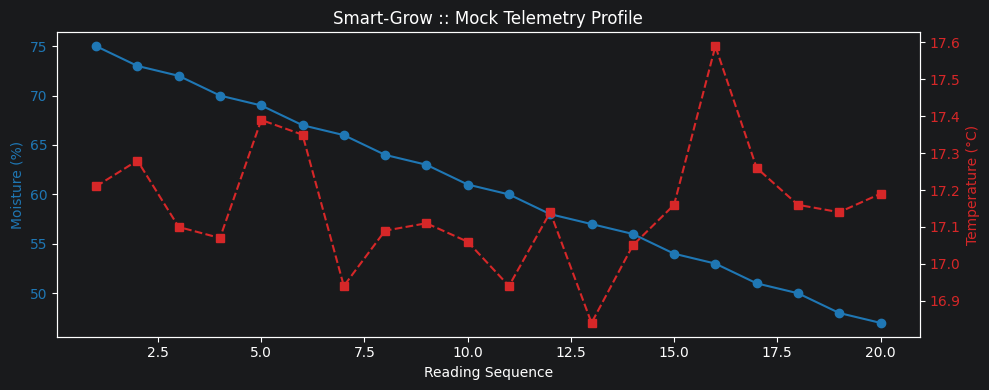

In [6]:
# Cell 3: Plot the simulated telemetry
fig, ax1 = plt.subplots(figsize=(10, 4))

ax1.set_xlabel('Reading Sequence')
ax1.set_ylabel('Moisture (%)', color='tab:blue')
ax1.plot(df['reading_id'], df['moisture'], color='tab:blue', marker='o', label='Moisture')
ax1.tick_params(axis='y', labelcolor='tab:blue')

ax2 = ax1.twinx()
ax2.set_ylabel('Temperature (°C)', color='tab:red')
ax2.plot(df['reading_id'], df['temperature'], color='tab:red', marker='s', linestyle='--', label='Temperature')
ax2.tick_params(axis='y', labelcolor='tab:red')

plt.title('Smart-Grow :: Mock Telemetry Profile')
fig.tight_layout()
plt.show()